In [180]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [181]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 
                        'PAY_0': 'PAY_1'})

In [182]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [183]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,def_pay
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [184]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      323
0       54
Name: count, dtype: int64

In [185]:
df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

In [186]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

In [187]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df = new_df.rename(columns={'PAY_3': 'July_Status', 
                        'PAY_4': 'June_Status',
                        'PAY_5': 'May_Status',
                        'PAY_6': 'April_Status',
                        'BILL_AMT2': 'August_Bill',
                        'BILL_AMT3': 'July_Bill',
                        'BILL_AMT4': 'June_Bill',
                        'BILL_AMT5': 'May_Bill',
                        'BILL_AMT6': 'April_Bill',
                        'PAY_AMT1': 'August_Pay',
                        'PAY_AMT2': 'July_Pay',
                        'PAY_AMT3': 'June_Pay',
                        'PAY_AMT4': 'May_Pay',
                        'PAY_AMT5': 'April_Pay'})

new_df.drop(columns=['ID'], inplace=True)

new_df['SEX'] = new_df.SEX.astype('category')
new_df['EDUCATION'] = new_df.EDUCATION.astype('category')
new_df['MARRIAGE'] = new_df.MARRIAGE.astype('category')
new_df['July_Status'] = new_df.July_Status.astype('category')
new_df['June_Status'] = new_df.June_Status.astype('category')
new_df['May_Status'] = new_df.May_Status.astype('category')
new_df['April_Status'] = new_df.April_Status.astype('category')

# Base Model Linear Regression

In [213]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['August_Pay']), new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16775.747652828817


Random Forest F1 Score: 0.7945516458569807


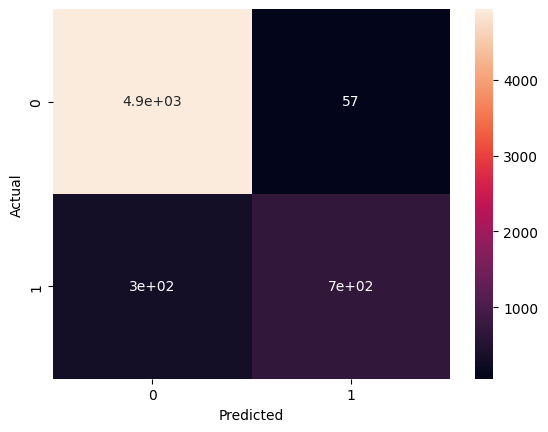

In [211]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import  f1_score

zero_new_df = new_df.copy()
# Create a binary target for zero vs non-zero payments
zero_new_df['Is_Zero'] = (zero_new_df['August_Pay'] == 0).astype(int)

# Split the data for the classification model
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(zero_new_df.drop(columns=['August_Pay', 'Is_Zero']), zero_new_df['Is_Zero'], test_size=0.2, random_state=42)

# Train the Random Forest classifier
forest_model = RandomForestClassifier(random_state=42, n_estimators=1000, max_depth=50)
forest_model.fit(X_train_class, y_train_class)

# Predict and evaluate the Random Forest classifier
y_pred_forest = forest_model.predict(X_test_class)
forest_accuracy = f1_score(y_test_class, y_pred_forest)
print(f"Random Forest F1 Score: {forest_accuracy}")

confuisson_matrix = pd.crosstab(y_test_class, y_pred_forest, rownames=['Actual'], colnames=['Predicted'])
sns.heatmap(confuisson_matrix, annot=True)
plt.show()


In [214]:
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")
print(f"RMSE: {root_mean_squared_error(y_test, ( 1 - y_pred_forest) * linear_model.predict(X_test))}")

RMSE: 16775.747652828817
RMSE: 16721.870737401958


In [ ]:
# Assuming 'df' is your DataFrame and 'columns_to_check' is the list of columns you want to check
columns_to_check = ['August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay', 'April_Bill', 'May_Bill', 'June_Bill', 'July_Bill', 'August_Bill']

# Select rows where any of the specified columns contain zeros
rows_with_zeros = new_df[(new_df[columns_to_check] == 0).any(axis=1)]

rows_with_zeros

X_train, X_test, y_train, y_test = train_test_split(rows_with_zeros.drop(columns=['August_Pay']), rows_with_zeros['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")



RMSE: 7042.821087564923


In [201]:
# Select rows where any of the specified columns contain zeros
rows_without_zeros = new_df[(new_df[columns_to_check] != 0).all(axis=1)]

rows_without_zeros

X_train, X_test, y_train, y_test = train_test_split(rows_without_zeros.drop(columns=['August_Pay']), rows_without_zeros['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 17839.485774642828


In [193]:
zero_new_df['Is_Zero'].value_counts()

Is_Zero
0    24747
1     5218
Name: count, dtype: int64

In [106]:

zero_ratios_specific = (new_df['August_Pay'] == 0).sum() / len(new_df)
print(zero_ratios_specific)

0.17413649257467045


# Feature Engineering

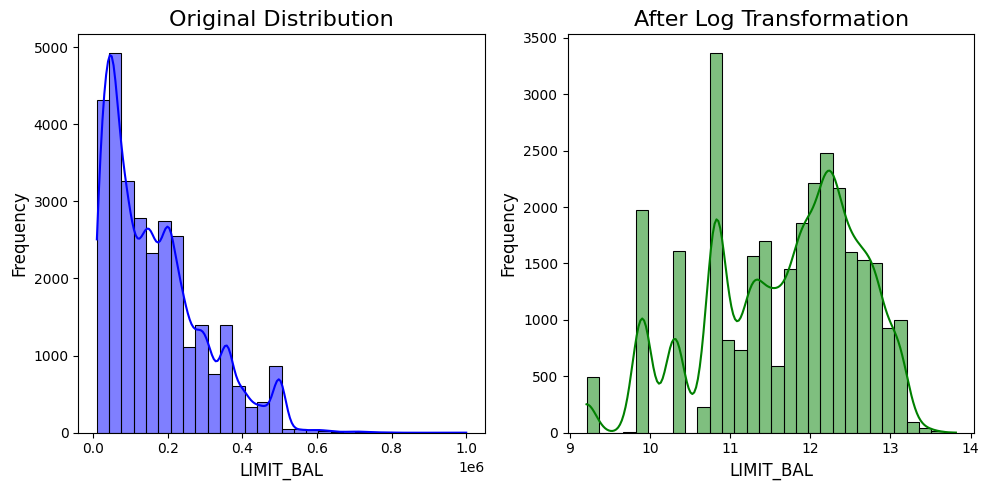

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

log_new_df = new_df.copy()

# Original Distribution
plt.subplot(1, 2, 1)
sns.histplot(new_df["LIMIT_BAL"], bins=30, kde=True, color="blue")
plt.title("Original Distribution",fontsize=16)
plt.xlabel("LIMIT_BAL", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation

# Scaled Distribution
plt.subplot(1, 2, 2)
sns.histplot(log_new_df["LIMIT_BAL"], bins=30, kde=True, color="green")
plt.title("After Log Transformation",fontsize=16)
plt.xlabel("LIMIT_BAL", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

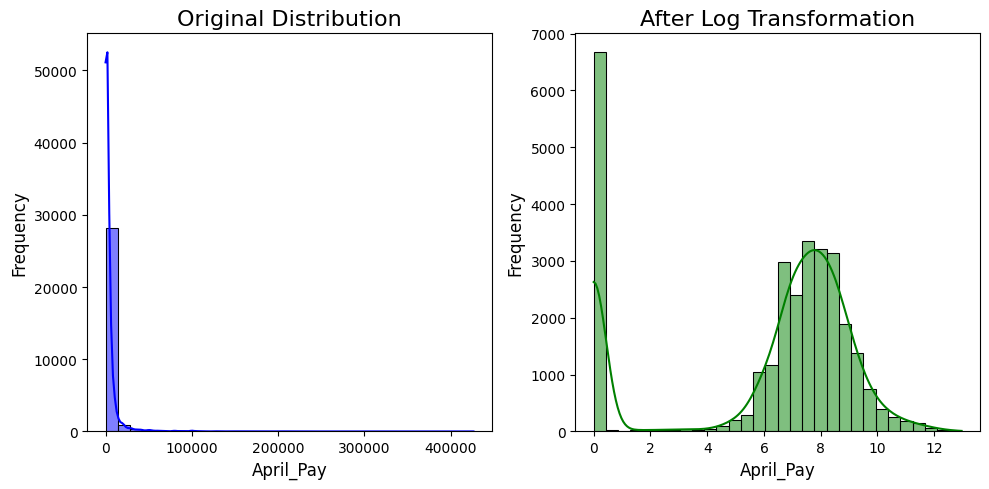

In [215]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

log_new_df = new_df.copy()

# Original Distribution
plt.subplot(1, 2, 1)
sns.histplot(new_df["April_Pay"], bins=30, kde=True, color="blue")
plt.title("Original Distribution",fontsize=16)
plt.xlabel("April_Pay", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

log_new_df["April_Pay"] = np.log1p(new_df["April_Pay"]) # Log transformation

# Scaled Distribution
plt.subplot(1, 2, 2)
sns.histplot(log_new_df["April_Pay"], bins=30, kde=True, color="green")
plt.title("After Log Transformation",fontsize=16)
plt.xlabel("April_Pay", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

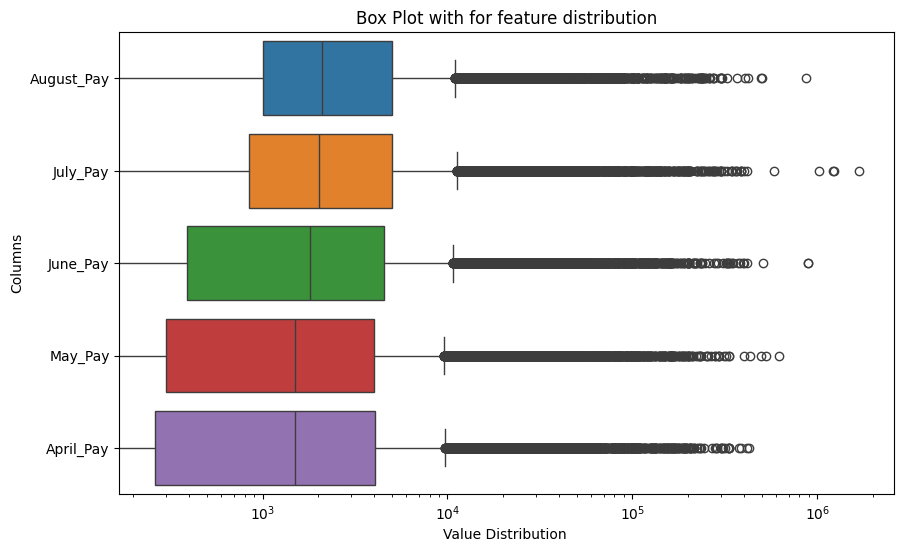

In [41]:
# Select numerical columns
num_cols = ['August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_df[num_cols], orient='h')
ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()

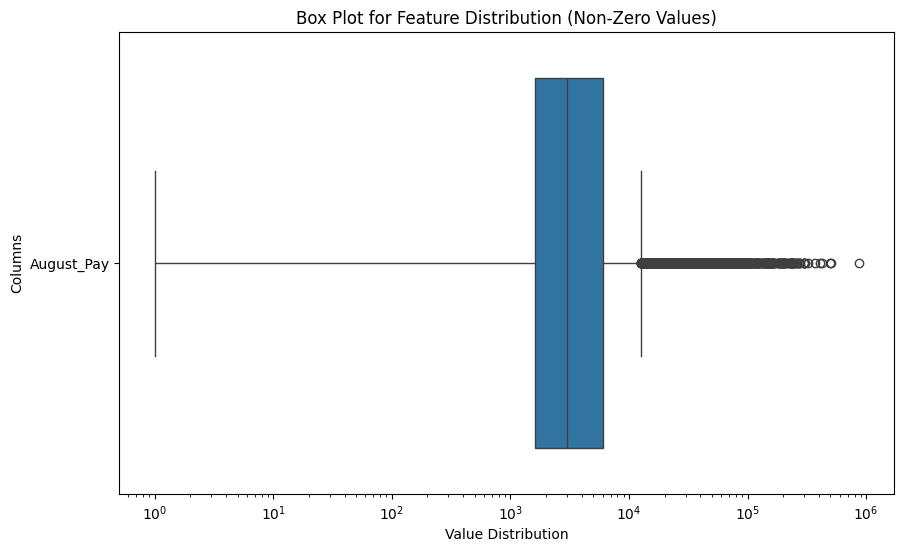

In [42]:
# Select numerical columns
num_cols = ['August_Pay']

# Filter out zero values
non_zero_df = new_df[num_cols].replace(0, np.nan).dropna()

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=non_zero_df, orient='h')
ax.set_xscale('log')
plt.xlabel("Value Distribution")
plt.ylabel("Columns")
plt.title("Box Plot for Feature Distribution (Non-Zero Values)")
plt.show()

In [43]:
non_zero_df

,August_Pay
2,1518.0
3,2000.0
4,2000.0
5,2500.0
6,55000.0
...,...
29994,7000.0
29995,8500.0
29996,1837.0
29998,85900.0


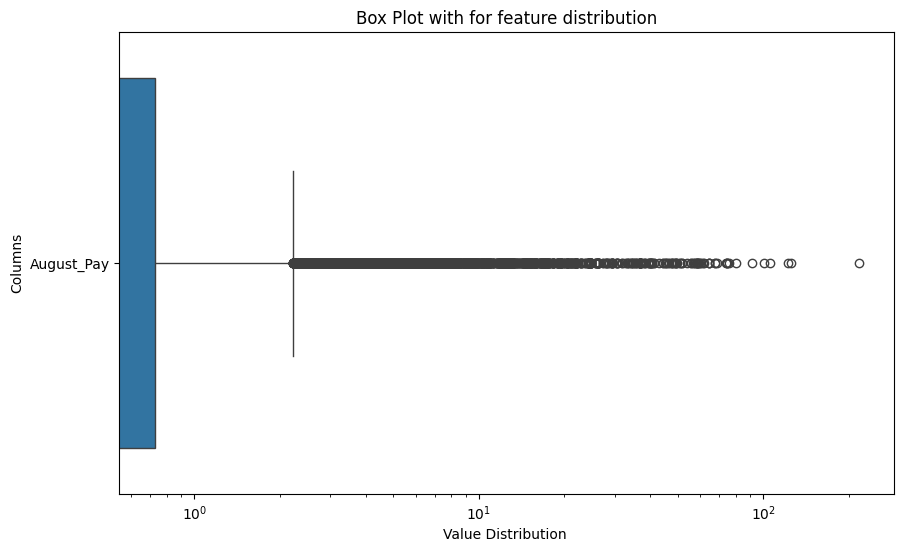

In [44]:
log_new_df = new_df.copy()

# Apply RobustScaler
scaler = RobustScaler()

log_new_df["April_Pay"] = scaler.fit_transform(log_new_df["April_Pay"].values.reshape(-1, 1))
log_new_df["May_Pay"] = scaler.fit_transform(log_new_df["May_Pay"].values.reshape(-1, 1))
log_new_df["June_Pay"] = scaler.fit_transform(log_new_df["June_Pay"].values.reshape(-1, 1))
log_new_df["July_Pay"] = scaler.fit_transform(log_new_df["July_Pay"].values.reshape(-1, 1))
log_new_df["August_Pay"] = scaler.fit_transform(log_new_df["August_Pay"].values.reshape(-1, 1))

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=log_new_df[num_cols], orient='h')
ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()

# log Transformation of Limit

In [60]:
log_new_df = new_df.copy()

log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)


linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
root_mean_squared_error(y_test, linear_model.predict(X_test))
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16752.577451881847


# Adding features for averaging (only non zeros) and without dropping

Zeros:
August_Bill     8.262973
July_Bill       9.477724
June_Bill      10.562323
May_Bill       11.600200
April_Bill     13.315535
August_Pay     17.413649
July_Pay       17.904222
June_Pay       19.813115
May_Pay        21.281495
April_Pay      22.265977
dtype: float64


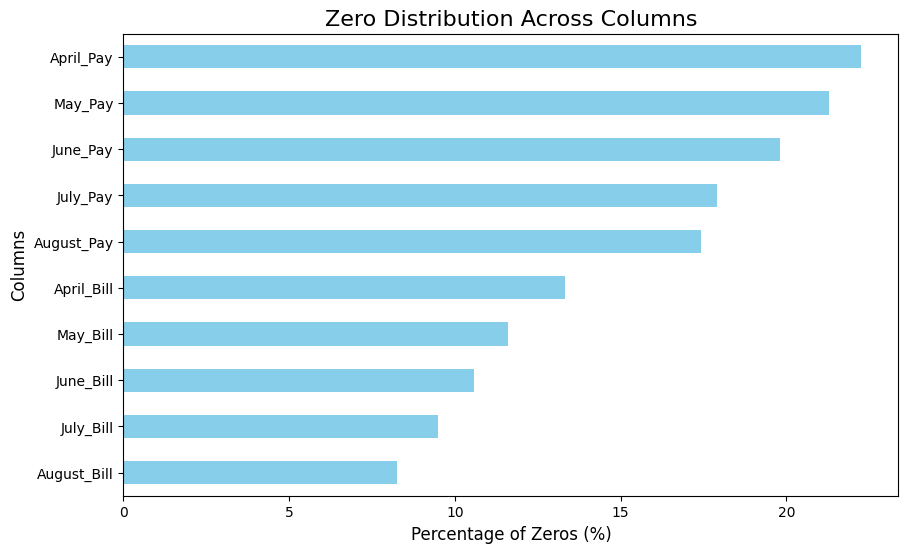

In [61]:
zero_percentage = (new_df[['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill', 'August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay']] == 0).mean() * 100
print('Zeros:')
print(zero_percentage)

plt.figure(figsize=(10, 6))
zero_percentage.sort_values().plot(kind='barh', color='skyblue')
plt.xlabel("Percentage of Zeros (%)",fontsize=12)
plt.ylabel("Columns",fontsize=12)
plt.title("Zero Distribution Across Columns",fontsize=16)
plt.show()

In [66]:
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 15697.363247735599


In [63]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df ["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
log_new_df["LIMIT_BAL_BIN"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)


X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 15704.974230398255


In [21]:
log_new_df.LIMIT_BAL_BIN.value_counts()

LIMIT_BAL_BIN
1     7673
2     4817
4     3970
3     3897
5     2900
6     2153
8     1546
7     1206
10    1024
9      573
11     206
Name: count, dtype: int64

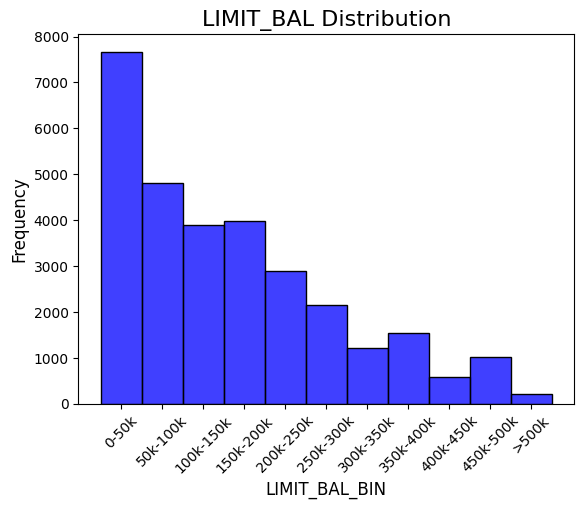

In [22]:
# Original Distribution
sns.histplot(log_new_df.LIMIT_BAL_BIN, bins=11, color="blue")
plt.title("LIMIT_BAL Distribution",fontsize=16)
plt.xlabel("LIMIT_BAL_BIN", fontsize=12)
plt.xticks(ticks=np.arange(1, 12), labels=["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"], rotation=45)
plt.ylabel("Frequency", fontsize=12)
plt.show()

# Smote

In [23]:
from imblearn.over_sampling import SMOTE


log_new_df ["LIMIT_BAL"] = new_df["LIMIT_BAL"] # without Log transformation

##########################################  SMOTE ##########################################

X_train_temp, X_test, _ , y_test = train_test_split(log_new_df, log_new_df['August_Pay'], test_size=0.2, random_state=42)

# Drop columns
X_test.drop(columns=['LIMIT_BAL_BIN', 'August_Pay'], inplace=True)
X_test ["LIMIT_BAL"] = np.log1p(X_test["LIMIT_BAL"]) # Log transformation

print("Before SMOTE:")
print(X_train_temp.LIMIT_BAL_BIN.value_counts())

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", 
                      "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", 
                      "August_Pay","July_Pay", "June_Pay", "May_Pay", "April_Pay"]
categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "AGE", "July_Status", "June_Status", "May_Status", "April_Status"]
target_column = "LIMIT_BAL_BIN"

# Separate numerical and categorical data
X_numerical = X_train_temp[numerical_features]
X_categorical = X_train_temp[categorical_features]  # Store categorical data separately
y = X_train_temp[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
smote_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
smote_df["LIMIT_BAL_BIN"] = pd.cut(smote_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(smote_df[target_column].value_counts())

smote_df.drop(columns=['LIMIT_BAL_BIN'], inplace=True)

# add features
smote_df ["LIMIT_BAL"] = np.log1p(smote_df["LIMIT_BAL"]) # Log transformation
smote_df ["AVG_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["AVG_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["MAX_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
smote_df ["MAX_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
smote_df ["MIN_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
smote_df ["MIN_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
smote_df ["PAY_SUM"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
smote_df ["BILL_SUM"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
smote_df ["CUM_PAY_JUN_JUL"] = smote_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL"] = smote_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_PAY_JUN_JUL_MAY"] = smote_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL_MAY"] = smote_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["STD_PAY"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

# Train-test split
y_train = smote_df.August_Pay
X_train = smote_df.drop(columns = ['August_Pay'])

cols = list(X_train.columns)
X_train = X_train[cols]
X_test = X_test[cols]

print(f"{X_train.shape}")
print(f"{X_test.shape}")

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")



Before SMOTE:
LIMIT_BAL_BIN
1     6168
2     3840
4     3189
3     3124
5     2310
6     1713
8     1239
7      972
10     795
9      454
11     168
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_BIN
1     6168
2     6168
3     6168
4     6168
5     6168
6     6168
7     6168
8     6168
9     6168
10    6168
11    6168
Name: count, dtype: int64
(67848, 31)
(5993, 31)
RMSE: 15206.293912539051


In [24]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 15206.293912539051


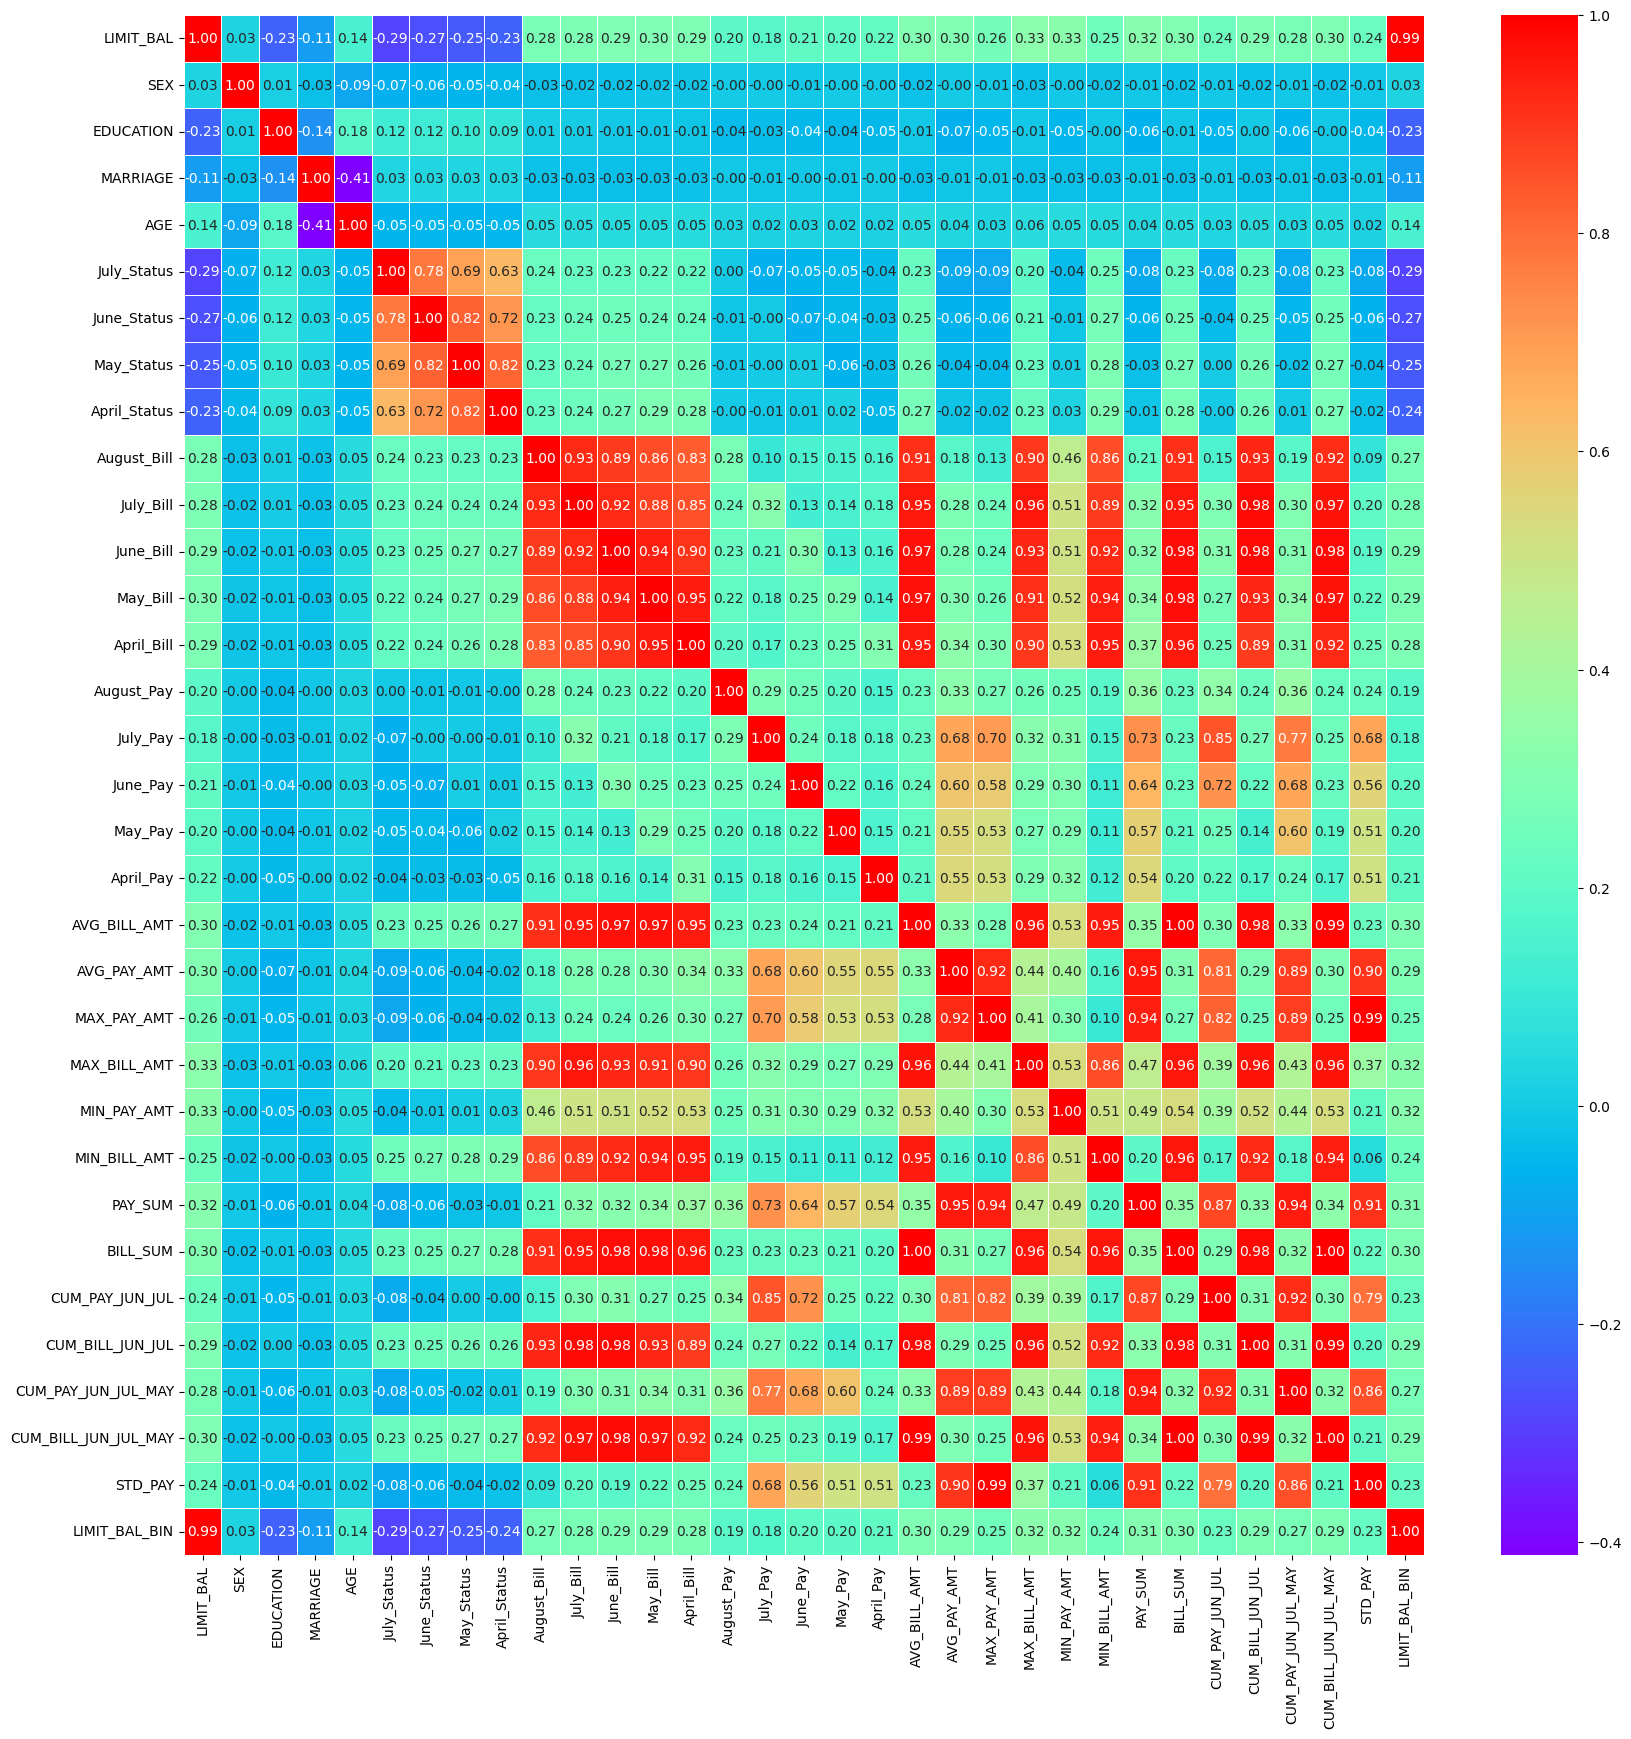

In [25]:
plt.figure(figsize=(20,20))
sns.heatmap(log_new_df.corr(),annot=True, cmap='rainbow',linewidth=0.5, fmt='.2f');

# Regression Models

In [179]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16775.747652828817


In [27]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)
tree_rmse = root_mean_squared_error(y_test, tree_model.predict(X_test))
print(f"Decision Tree RMSE: {tree_rmse}")

Decision Tree RMSE: 24014.748951531183


In [80]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
forest_rmse = root_mean_squared_error(y_test, forest_model.predict(X_test))
print(f"Random Forest RMSE: {forest_rmse}")

Random Forest RMSE: 18056.44956506618


In [ ]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(random_state=42)
lasso_model.fit(X_train, y_train)
lasso_rmse = root_mean_squared_error(y_test, lasso_model.predict(X_test))
print(f"Lasso RMSE: {lasso_rmse}")

Lasso RMSE: 15190.404138796514


In [174]:
from sklearn.neural_network import MLPRegressor

# Initialize the MLPRegressor
mlp_model = MLPRegressor(random_state=42, max_iter=1000, hidden_layer_sizes=(100, 50), alpha=0.01)

# Fit the model
mlp_model.fit(X_train, y_train)

# Predict and calculate RMSE
mlp_rmse = root_mean_squared_error(y_test, mlp_model.predict(X_test))
print(f"MLP Regressor RMSE: {mlp_rmse}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mlp_model.fit(X_train_scaled, y_train)
mlp_rmse = root_mean_squared_error(y_test, mlp_model.predict(X_test_scaled))
print(f"MLP Regressor RMSE: {mlp_rmse}")

MLP Regressor RMSE: 16968.57357602999
MLP Regressor RMSE: 16006.98516807627


In [178]:
print(f"RMSE: {root_mean_squared_error(y_test, ( 1 - y_pred_forest) * mlp_model.predict(X_test_scaled))}")

RMSE: 15993.685681401479


In [81]:
from sklearn.linear_model import HuberRegressor

model = HuberRegressor(epsilon=1.35)  # Less sensitive to outliers
model.fit(X_train, y_train)
huber_rmse = root_mean_squared_error(y_test, model.predict(X_test))
print(f"Huber Regressor RMSE: {huber_rmse}")

Huber Regressor RMSE: 17133.224536664693


In [82]:
from sklearn.linear_model import TweedieRegressor

model = TweedieRegressor (power=1.5, alpha=0.1,)
model.fit(X_train, y_train)
tweedie_rmse = root_mean_squared_error(y_test, model.predict(X_test))
print(f"Tweedie Regressor RMSE: {tweedie_rmse}")


Tweedie Regressor RMSE: 20728.34928773671


In [83]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train, y_train)
knn_rmse = root_mean_squared_error(y_test, model.predict(X_test))
print(f"KNN Regressor RMSE: {knn_rmse}")


KNN Regressor RMSE: 19698.453732740152


In [84]:
from sklearn.linear_model import QuantileRegressor

model = QuantileRegressor(quantile=0.5, alpha=0.1)
model.fit(X_train, y_train)
quantile_rmse = root_mean_squared_error(y_test, model.predict(X_test))
print(f"Quantile Regressor RMSE: {quantile_rmse}")

Quantile Regressor RMSE: 17124.849725526747


In [86]:
model = QuantileRegressor()
model.fit(X_train_scaled, y_train)
quantile_rmse = root_mean_squared_error(y_test, model.predict(X_test_scaled))
print(f"Quantile Regressor RMSE: {quantile_rmse}")

Quantile Regressor RMSE: 21056.506474767102
